In [8]:
from tokenizers import Tokenizer
import torch
import matplotlib.pyplot as plt

# Tokenizadores

In [9]:
tokenizador = Tokenizer.from_file("./data/tokenizer.json")
texto = "O gato dorme"

tokens = [5, 8, 2, 9, 4, 7]
context_size = 3
stride = 1

In [10]:
resultado = tokenizador.encode(texto)
# ['O', 'Ġga', 'to', 'Ġdor', 'me'] => Ġ representa espaço
print(resultado.tokens)
print(resultado.ids)

['O', 'Ġga', 'to', 'Ġdor', 'me']
[47, 4326, 287, 4956, 547]


In [11]:
texto_reconstruido = tokenizador.decode(resultado.ids)
print(texto_reconstruido)
print(texto_reconstruido == texto)

O gato dorme
True


# Ids

In [12]:
entrada = resultado.ids[:-1]
alvo = resultado.ids[1:]

print(entrada, alvo)

[47, 4326, 287, 4956] [4326, 287, 4956, 547]


# Stride

In [13]:
for i in range(0, len(tokens) - context_size, stride):
    print("i = ", i)
    x = tokens[i: i + context_size]
    y = tokens[i + 1: i + context_size + 1]
    print(x, y)

i =  0
[5, 8, 2] [8, 2, 9]
i =  1
[8, 2, 9] [2, 9, 4]
i =  2
[2, 9, 4] [9, 4, 7]


# Tensores

In [14]:
x = []
y = []

for i in range(0, len(tokens) - context_size, stride):
    print("i = ", i)
    x.append(tokens[i: i + context_size])
    y.append(tokens[i + 1: i + context_size + 1])
    print(x, y)
    
tensor_x = torch.tensor(x, dtype=torch.long)
tensor_y = torch.tensor(y, dtype=torch.long)
print(tensor_x, tensor_y)
print(tensor_x.shape)
print(tensor_y.shape)

i =  0
[[5, 8, 2]] [[8, 2, 9]]
i =  1
[[5, 8, 2], [8, 2, 9]] [[8, 2, 9], [2, 9, 4]]
i =  2
[[5, 8, 2], [8, 2, 9], [2, 9, 4]] [[8, 2, 9], [2, 9, 4], [9, 4, 7]]
tensor([[5, 8, 2],
        [8, 2, 9],
        [2, 9, 4]]) tensor([[8, 2, 9],
        [2, 9, 4],
        [9, 4, 7]])
torch.Size([3, 3])
torch.Size([3, 3])


# Batch

In [15]:
batch_size = 2


def batching(tensor_list, size=batch_size):
    batch = []
    for i in range(0, len(tensor_list), size):
        batch.append(tensor_list[i : i + size])

    return batch


batched_x = batching(tensor_x)
batched_y = batching(tensor_y)

print(batched_x, batched_y)
print(len(batched_x), len(batched_y))

[tensor([[5, 8, 2],
        [8, 2, 9]]), tensor([[2, 9, 4]])] [tensor([[8, 2, 9],
        [2, 9, 4]]), tensor([[9, 4, 7]])]
2 2


# Embeddings

In [16]:
num_embeddings = 10
num_dimensions = 4

embeddings = torch.nn.Embedding(num_embeddings, num_dimensions)

In [17]:
token_vectors = embeddings(batched_x[0])

print(token_vectors)
print("Tabela:", embeddings.weight.shape)
print("Entrada:", batched_x[0].shape)
print("Resultado:", token_vectors.shape)
print(embeddings.weight[8])

tensor([[[-0.0299,  0.4153,  0.3582,  0.6343],
         [-1.2062,  0.9675,  0.2668, -0.4387],
         [-1.4161, -0.6323,  1.2021,  0.8014]],

        [[-1.2062,  0.9675,  0.2668, -0.4387],
         [-1.4161, -0.6323,  1.2021,  0.8014],
         [-0.2267,  0.5428, -0.8940, -0.0691]]], grad_fn=<EmbeddingBackward0>)
Tabela: torch.Size([10, 4])
Entrada: torch.Size([2, 3])
Resultado: torch.Size([2, 3, 4])
tensor([-1.2062,  0.9675,  0.2668, -0.4387], grad_fn=<SelectBackward0>)


# Posição

In [18]:
num_linhas = 3
num_componentes = 4

posicao = torch.nn.Embedding(num_linhas, num_componentes)
value = torch.arange(num_linhas)

In [19]:
position_vectors = posicao(value)
print(position_vectors, position_vectors.shape)

tensor([[ 0.0148,  0.5381,  0.9423, -0.3440],
        [-0.0887, -0.8154, -0.4221,  1.2044],
        [ 1.3050, -0.4716, -1.0993,  0.3402]], grad_fn=<EmbeddingBackward0>) torch.Size([3, 4])


In [20]:
input_vectors = position_vectors + token_vectors
print(input_vectors, input_vectors.shape)
print("Tokens:", token_vectors)
print("Posições:", position_vectors)

tensor([[[-0.0151,  0.9534,  1.3005,  0.2903],
         [-1.2949,  0.1521, -0.1553,  0.7657],
         [-0.1111, -1.1040,  0.1028,  1.1417]],

        [[-1.1914,  1.5056,  1.2091, -0.7828],
         [-1.5048, -1.4478,  0.7800,  2.0058],
         [ 1.0783,  0.0711, -1.9932,  0.2711]]], grad_fn=<AddBackward0>) torch.Size([2, 3, 4])
Tokens: tensor([[[-0.0299,  0.4153,  0.3582,  0.6343],
         [-1.2062,  0.9675,  0.2668, -0.4387],
         [-1.4161, -0.6323,  1.2021,  0.8014]],

        [[-1.2062,  0.9675,  0.2668, -0.4387],
         [-1.4161, -0.6323,  1.2021,  0.8014],
         [-0.2267,  0.5428, -0.8940, -0.0691]]], grad_fn=<EmbeddingBackward0>)
Posições: tensor([[ 0.0148,  0.5381,  0.9423, -0.3440],
        [-0.0887, -0.8154, -0.4221,  1.2044],
        [ 1.3050, -0.4716, -1.0993,  0.3402]], grad_fn=<EmbeddingBackward0>)


# Atenção

In [21]:
camadas_lineares = [
    torch.nn.Linear(4, 4, bias=False),
    torch.nn.Linear(4, 4, bias=False),
    torch.nn.Linear(4, 4, bias=False),
]

chamadas = []

for linear in camadas_lineares:
    chamadas.append(linear(input_vectors))

queries, keys, values = chamadas
chamadas = []

print(queries, keys, values)

tensor([[[ 0.8031, -0.4667,  0.1348,  0.5322],
         [ 0.5883, -0.4713,  0.2100,  0.1515],
         [-0.1965,  0.5108, -0.4442, -0.2283]],

        [[ 1.4910, -1.4455,  1.1834,  1.1309],
         [ 0.6735, -0.0107, -0.0292,  0.2808],
         [-1.3714,  0.9757, -1.1077, -1.2707]]], grad_fn=<UnsafeViewBackward0>) tensor([[[-0.8545,  0.8883,  0.6142, -0.7981],
         [ 0.5501, -0.7480, -0.5368, -0.5304],
         [ 1.0140, -0.6479, -0.1547,  0.1551]],

        [[-1.4069,  0.7535,  0.3362, -1.0315],
         [ 1.4873, -1.2578, -0.3793, -0.3929],
         [ 0.8085, -0.4769, -0.5943,  0.6105]]], grad_fn=<UnsafeViewBackward0>) tensor([[[ 0.5273, -0.5115,  0.4938,  0.5466],
         [-0.1484, -0.5607, -0.1022, -0.1841],
         [ 0.2466, -0.0581, -0.0144, -0.2540]],

        [[-0.1357, -0.6093,  0.2081,  0.6893],
         [ 0.2543, -0.6130, -0.0266, -0.2106],
         [-0.0846,  0.3557, -0.1949, -0.7206]]], grad_fn=<UnsafeViewBackward0>)


In [22]:
resultado_produto_escalar = []
for i in range(3):
    resultado_produto_escalar.append(sum(queries[0, 1] * keys[0, i]))
    
tensor_pe = torch.stack(resultado_produto_escalar)
half_tensor_pe = tensor_pe/2
print(resultado_produto_escalar)
print(tensor_pe)
print(half_tensor_pe)


[tensor(-0.9133, grad_fn=<AddBackward0>), tensor(0.4831, grad_fn=<AddBackward0>), tensor(0.8929, grad_fn=<AddBackward0>)]
tensor([-0.9133,  0.4831,  0.8929], grad_fn=<StackBackward0>)
tensor([-0.4567,  0.2415,  0.4464], grad_fn=<DivBackward0>)


In [23]:
mascara = half_tensor_pe.clone()
mascara[2] = float("-inf")
print(mascara)

tensor([-0.4567,  0.2415,    -inf], grad_fn=<CopySlices>)


In [24]:
attention_weights = torch.softmax(mascara, dim=0)
print(attention_weights)
print(attention_weights.sum())

tensor([0.3322, 0.6678, 0.0000], grad_fn=<SoftmaxBackward0>)
tensor(1., grad_fn=<SumBackward0>)


In [25]:
weighted_vectors = []
for i in range(3):
    weighted_vectors.append(attention_weights[i]*values[0, i])
    
weighted_vectors = torch.stack(weighted_vectors)
print(weighted_vectors)
print(weighted_vectors.sum(dim=0))

tensor([[ 0.1752, -0.1699,  0.1640,  0.1816],
        [-0.0991, -0.3745, -0.0683, -0.1229],
        [ 0.0000, -0.0000, -0.0000, -0.0000]], grad_fn=<StackBackward0>)
tensor([ 0.0761, -0.5444,  0.0958,  0.0586], grad_fn=<SumBackward1>)


# Implementando atenção

In [26]:
chamadas = []
camadas_lineares = [
    torch.nn.Linear(4, 4, bias=False),
    torch.nn.Linear(4, 4, bias=False),
    torch.nn.Linear(4, 4, bias=False),
]

for linear in camadas_lineares:
    chamadas.append(linear(input_vectors))

queries, keys, values = chamadas

In [27]:
# deprecated
def calcular_pontuacoes_test(queries, keys):
    save3 = []

    for i in range(len(queries)):
        save2 = []
        for j in range(len(queries[i])):
            save = []
            for k in range(len(queries[i])):
                save.append(sum(queries[i, j] * keys[i, k]) / 2)

            save2.append(torch.stack(save))

        save3.append(torch.stack(save2))

    return torch.stack(save3)

In [28]:
# New
def calcular_pontuacoes(queries, keys):
    dimensao = keys.shape[-1] ** 0.5
    transposed_keys = keys.transpose(-2, -1)
    return (queries @ transposed_keys) / dimensao

In [29]:
# deprecated
def sliding_mascara(tensors):
    mascaras = []
    for index in range(len(tensors)):
        print(tensors[index])
        mascara = tensors[index].clone()
        mascara[index + 1 : len(mascara)] = float("-inf")
        mascaras.append(mascara)

    return torch.stack(mascaras)

In [30]:
# new
def aplicar_mascara_causal(pontuacoes):
    pontuacoes_mascara = pontuacoes.clone()
    for exemplos_index in range(len(pontuacoes_mascara)):
        tokens_tamanho = len(pontuacoes_mascara[exemplos_index])
        for tokens_index in range(tokens_tamanho):
            pontuacoes_mascara[exemplos_index][tokens_index][tokens_index + 1 : tokens_tamanho] = float("-inf")

    return pontuacoes_mascara


In [31]:
def calcular_pesos(pontuacoes_mascaradas):
    return torch.softmax(pontuacoes_mascaradas, dim=-1)

In [32]:
def combinar_values(pesos, values):
    return pesos @ values

In [33]:
def atencao_causal(queries, keys, values):
    tensor_pe = calcular_pontuacoes(queries, keys)
    pontuacoes_mascaradas = aplicar_mascara_causal(tensor_pe)
    pesos = calcular_pesos(pontuacoes_mascaradas)
    contextos = combinar_values(pesos, values)
    return pesos, contextos

In [34]:
pesos, contextos = atencao_causal(queries, keys, values)

# Testes

In [35]:
test2 = pesos @ values
print(test2.shape)
print(torch.allclose(contextos, test2))

torch.Size([2, 3, 4])
True


# Validação se altera o futuro

In [36]:
queries_clone = queries.clone()
keys_clone = keys.clone()
values_clone = values.clone()

queries_clone[0][2] += 10
keys_clone[0][2] += 10
values_clone[0][2] += 10

In [37]:
pesos_clone, contexto_clone = atencao_causal(queries_clone, keys_clone, values_clone)
print(torch.allclose(contexto_clone[0][0], contextos[0][0]))
print(torch.allclose(contexto_clone[0][1], contextos[0][1]))


True
True


# Melhorando atencao

In [38]:
class AtencaoCausal(torch.nn.Module):
    def __init__(self, dimensao_entrada, dimensao_saida=0):
        super().__init__()
        self.dimensao_entrada = dimensao_entrada
        self.dimensao_saida = (
            dimensao_entrada if dimensao_saida <= 0 else dimensao_saida
        )
        self.camada_linear_query = torch.nn.Linear(
            dimensao_entrada, self.dimensao_saida, bias=False
        )
        self.camada_linear_key = torch.nn.Linear(
            dimensao_entrada, self.dimensao_saida, bias=False
        )
        self.camada_linear_value = torch.nn.Linear(
            dimensao_entrada, self.dimensao_saida, bias=False
        )

    def forward(self, x):
        queries = self.camada_linear_query(x)
        keys = self.camada_linear_key(x)
        values = self.camada_linear_value(x)
        return atencao_causal(queries, keys, values)

In [39]:
atencao_cabeça_1 = AtencaoCausal(4, 2)
atencao_cabeça_2 = AtencaoCausal(4, 2)


In [40]:
peso_atencao_1, contexto_atencao_1 = atencao_cabeça_1(input_vectors)
print(peso_atencao_1, contexto_atencao_1)
peso_atencao_2, contexto_atencao_2 = atencao_cabeça_2(input_vectors)
print(peso_atencao_2, contexto_atencao_2)

tensor([[[1.0000, 0.0000, 0.0000],
         [0.4364, 0.5636, 0.0000],
         [0.2548, 0.3381, 0.4071]],

        [[1.0000, 0.0000, 0.0000],
         [0.4370, 0.5630, 0.0000],
         [0.2126, 0.4936, 0.2938]]], grad_fn=<SoftmaxBackward0>) tensor([[[-1.1290,  0.2353],
         [-0.2933, -0.0413],
         [-0.0203,  0.1873]],

        [[-0.7750, -0.4917],
         [-0.0128,  0.1418],
         [ 0.2673,  0.1307]]], grad_fn=<UnsafeViewBackward0>)
tensor([[[1.0000, 0.0000, 0.0000],
         [0.4927, 0.5073, 0.0000],
         [0.2970, 0.3279, 0.3751]],

        [[1.0000, 0.0000, 0.0000],
         [0.4460, 0.5540, 0.0000],
         [0.1035, 0.5958, 0.3008]]], grad_fn=<SoftmaxBackward0>) tensor([[[ 0.5377, -0.4443],
         [ 0.3206, -0.5025],
         [ 0.2954, -0.5221]],

        [[-0.0687, -0.2969],
         [ 0.1982, -0.9429],
         [ 0.2548, -0.6606]]], grad_fn=<UnsafeViewBackward0>)


In [41]:
contexto_cabecas = torch.cat(
    (contexto_atencao_1, contexto_atencao_2), dim=2
)

projecao_saida = torch.nn.Linear(4, 4, bias=False)
contexto_projetado = projecao_saida(contexto_cabecas)

print(contexto_projetado)
print(contexto_projetado.shape)

tensor([[[-0.2169,  0.0013, -0.4422,  0.5326],
         [-0.0073,  0.0910, -0.3724,  0.2642],
         [-0.0476,  0.0019, -0.4099,  0.2878]],

        [[ 0.0384,  0.2972, -0.0200,  0.0680],
         [-0.0468,  0.1242, -0.5644,  0.3864],
         [ 0.0125,  0.0395, -0.4636,  0.2521]]], grad_fn=<UnsafeViewBackward0>)
torch.Size([2, 3, 4])


# Atenção de multiplas cabeças

In [42]:
class AtencaoMultiplasCabecas(torch.nn.Module):
    def __init__(self, dimensao_entrada, dimensao_saida=0, qtd_cabecas=1):
        super().__init__()
        self.dimensao_entrada = dimensao_entrada

        self.dimensao_saida = (
            dimensao_entrada if dimensao_saida <= 0 else dimensao_saida
        )

        if qtd_cabecas <= 0:
            raise ValueError(
                "A quantidade de cabeças precisa ser maior que zero."
            )

        if self.dimensao_saida % qtd_cabecas != 0:
            raise ValueError(
                "A dimensão de saída precisa ser divisível pela quantidade de cabeças."
            )

        self.qtd_cabecas = qtd_cabecas

        self.cabecas = torch.nn.ModuleList(
            [
                AtencaoCausal(
                    dimensao_entrada,
                    self.dimensao_saida // self.qtd_cabecas,
                )
                for _ in range(self.qtd_cabecas)
            ]
        )

        self.saida_linear = torch.nn.Linear(
            self.dimensao_saida,
            self.dimensao_saida,
            bias=False,
        )

    def forward(self, x):
        cabecas_atencao_contextos = []

        for index in range(len(self.cabecas)):
            cabecas_atencao_contextos.append(
                self.cabecas[index](x)[1]
            )

        cabecas_atencao = torch.cat(
            cabecas_atencao_contextos, dim=2
        )

        return self.saida_linear(cabecas_atencao)

In [43]:
multi_cabecas = AtencaoMultiplasCabecas(4, 4, 2)
saida_multi_cabecas = multi_cabecas(input_vectors)

print(saida_multi_cabecas)
print(saida_multi_cabecas.shape)

clone_input_vector = input_vectors.clone()
clone_input_vector[0, 2] += 10

saida_multi_cabecas_clone = multi_cabecas(clone_input_vector)

print(
    torch.allclose(
        saida_multi_cabecas_clone[0, 0],
        saida_multi_cabecas[0, 0],
    )
)

print(
    torch.allclose(
        saida_multi_cabecas_clone[0, 1],
        saida_multi_cabecas[0, 1],
    )
)

tensor([[[ 0.1148, -0.0470, -0.0119,  0.1091],
         [ 0.1251, -0.1379,  0.2914,  0.0851],
         [ 0.2164, -0.2403,  0.3072,  0.3992]],

        [[-0.0031,  0.2280,  0.1846, -0.8556],
         [ 0.0929,  0.0217,  0.3439, -0.4188],
         [ 0.5232, -0.2402,  0.4678,  0.4209]]], grad_fn=<UnsafeViewBackward0>)
torch.Size([2, 3, 4])
True
True


# Normalização

In [44]:
saida_residual = input_vectors + saida_multi_cabecas

print(saida_residual)
print(saida_residual.shape)

tensor([[[ 0.0997,  0.9064,  1.2886,  0.3994],
         [-1.1698,  0.0142,  0.1361,  0.8507],
         [ 0.1054, -1.3443,  0.4099,  1.5408]],

        [[-1.1944,  1.7336,  1.3936, -1.6383],
         [-1.4119, -1.4261,  1.1238,  1.5870],
         [ 1.6015, -0.1691, -1.5254,  0.6921]]], grad_fn=<AddBackward0>)
torch.Size([2, 3, 4])


In [45]:
vetor_teste = torch.tensor([1.0, 3.0, 5.0, 7.0])

media = vetor_teste.mean()
var = vetor_teste.var(unbiased=False)
normalizacao = (vetor_teste - media) / (var + 1e-5) ** 0.5

print("Vetor: ", vetor_teste)
print("Média: ", media)
print("Variância: ", var)
print("Vetor normalizado: ", normalizacao)

Vetor:  tensor([1., 3., 5., 7.])
Média:  tensor(4.)
Variância:  tensor(5.)
Vetor normalizado:  tensor([-1.3416, -0.4472,  0.4472,  1.3416])


In [46]:
def normalizacao(vetor):
    media = vetor.mean(dim=2, keepdim=True)
    var = vetor.var(unbiased=False, dim=2, keepdim=True)
    normalizacao = (vetor - media) / (var + 1e-5) ** 0.5
    return normalizacao

In [47]:
print(normalizacao(saida_residual))

tensor([[[-1.2544,  0.5092,  1.3446, -0.5993],
         [-1.5548,  0.0777,  0.2458,  1.2313],
         [-0.0706, -1.4796,  0.2255,  1.3247]],

        [[-0.8437,  1.1044,  0.8782, -1.1390],
         [-0.9880, -0.9982,  0.8273,  1.1589],
         [ 1.2601, -0.2768, -1.4540,  0.4707]]], grad_fn=<DivBackward0>)


# LayerNorm

In [48]:
class LayerNorm(torch.nn.Module):
    def __init__(self, qtd_componentes):
        super().__init__()
        self.qtd_componentes = qtd_componentes
        self.epsilon = 1e-5
        self.vetor_escala = torch.nn.Parameter(torch.ones(qtd_componentes))
        self.vetor_deslocamento = torch.nn.Parameter(torch.zeros(qtd_componentes))

    def forward(self, x):
        normalizado = self.normalizacao(x)
        resultado = self.vetor_escala * normalizado + self.vetor_deslocamento
        return resultado

    def normalizacao(self, vetor, eixo=-1):
        media = vetor.mean(dim=eixo, keepdim=True)
        var = vetor.var(unbiased=False, dim=eixo, keepdim=True)
        normalizacao = (vetor - media) / (var + self.epsilon) ** 0.5
        return normalizacao

In [49]:
layer = LayerNorm(4)
layer_saida_residual = layer(saida_residual)
print(layer_saida_residual)

tensor([[[-1.2544,  0.5092,  1.3446, -0.5993],
         [-1.5548,  0.0777,  0.2458,  1.2313],
         [-0.0706, -1.4796,  0.2255,  1.3247]],

        [[-0.8437,  1.1044,  0.8782, -1.1390],
         [-0.9880, -0.9982,  0.8273,  1.1589],
         [ 1.2601, -0.2768, -1.4540,  0.4707]]], grad_fn=<AddBackward0>)


# MLP

In [50]:
class MLP(torch.nn.Module):
    def __init__(self, dimensao):
        super().__init__()
        self.dimensao = dimensao
        self.expansao = torch.nn.Linear(dimensao, 4 * dimensao)
        self.ativacao = torch.nn.GELU()
        self.projecao_saida = torch.nn.Linear(4 * dimensao, dimensao)

    def forward(self, x):
        expansao_vetor = self.expansao(x)
        ativacao_vetor = self.ativacao(expansao_vetor)
        projecao_saida_vetor = self.projecao_saida(ativacao_vetor)
        return projecao_saida_vetor

In [51]:
mlp = MLP(4)
mlp_saida_residual = mlp(layer_saida_residual)

In [52]:
conexao_residual_mlp = saida_residual + mlp_saida_residual

# print(layer_saida_residual)
# print(mlp_saida_residual)
print(conexao_residual_mlp)

tensor([[[ 0.2833,  1.3695,  1.7976,  0.5220],
         [-0.9359,  0.4969,  0.2269,  1.2776],
         [ 0.1778, -0.8704,  0.4262,  2.3086]],

        [[-1.0242,  2.0552,  1.7190, -1.5962],
         [-1.2946, -0.8837,  1.3134,  2.2184],
         [ 1.6825,  0.1453, -1.8083,  1.1002]]], grad_fn=<AddBackward0>)


In [53]:
class BlocoTransformer(torch.nn.Module):
    def __init__(self, dimensao, qtd_cabecas):
        super().__init__()
        self.norm_atencao = LayerNorm(dimensao)
        self.atencao = AtencaoMultiplasCabecas(dimensao,dimensao, qtd_cabecas)
        self.norm_mlp = LayerNorm(dimensao)
        self.mlp = MLP(dimensao)
        
    def forward(self, x):
        entrada = self.norm_atencao(x)
        entrada_normalizada = self.atencao(entrada)
        residual_atencao = x + entrada_normalizada
        residual_normalizada = self.norm_mlp(residual_atencao)
        saida_mlp = self.mlp(residual_normalizada)
        saida_bloco = residual_atencao + saida_mlp
        return saida_bloco

In [54]:
bloco_transformer = BlocoTransformer(4, 2)
saida_bloco = bloco_transformer(input_vectors)

In [55]:
camada_linear = torch.nn.Linear(4, 10, bias=False)
logits = camada_linear(saida_bloco)

In [56]:
print(torch.argmax(logits, dim=-1))
print(batched_y[0])

tensor([[3, 9, 8],
        [4, 9, 5]])
tensor([[8, 2, 9],
        [2, 9, 4]])


In [57]:
softmax_logits = torch.softmax(logits[0][0], dim=0)
log = -torch.log(softmax_logits[8])
print(log)

tensor(2.5355, grad_fn=<NegBackward0>)


In [58]:
save_error = []
choosen_batch = batched_y[0]
for i in range(len(choosen_batch)):
    save_error_example = []
    for j in range(len(choosen_batch[i])):
        softmax_logits = torch.softmax(logits[i][j], dim=0)
        save_error_example.append(-torch.log(softmax_logits[choosen_batch[i, j]]))

    save_error.append(torch.stack(save_error_example))

resultado = torch.stack(save_error)
print(resultado)
print(resultado.mean())

tensor([[2.5355, 2.2355, 2.0107],
        [1.8177, 1.3757, 2.6439]], grad_fn=<StackBackward0>)
tensor(2.1032, grad_fn=<MeanBackward0>)


In [59]:
logits_entropia = logits.reshape(-1, logits.shape[-1])
batch_entropia = batched_y[0].reshape(-1)
print(logits_entropia)
print(batch_entropia)

tensor([[-0.0152,  0.2036,  0.2908,  0.6271,  0.3745,  0.2173,  0.0306, -0.9053,
         -0.0292,  0.5514],
        [ 0.5898, -0.0802,  0.2984, -0.5233,  0.3786, -0.5619,  0.6171,  0.3759,
         -0.4468,  0.6708],
        [ 0.2070, -0.4594, -0.4132,  0.0355, -0.3769, -0.3878, -0.6358,  0.2250,
          0.4407,  0.2445],
        [ 0.0270,  0.3873,  0.9628,  0.5913,  1.0109,  0.3452,  0.7268, -1.1390,
         -0.1663,  0.5916],
        [ 1.1525, -0.8762, -0.4380, -0.7782, -0.2651, -1.4597, -0.2721,  1.0709,
          0.0391,  1.2580],
        [-0.5319,  0.3686, -0.2803, -0.2683, -0.3933,  0.4908,  0.0676,  0.3783,
         -0.3003, -1.0194]], grad_fn=<ViewBackward0>)
tensor([8, 2, 9, 2, 9, 4])


In [60]:
erro = torch.nn.functional.cross_entropy(logits_entropia, batch_entropia)
erro.backward()

In [61]:
print(camada_linear.weight.grad)
print(camada_linear.weight.grad.shape)

tensor([[-0.0850, -0.0380,  0.0686,  0.0640],
        [-0.0092,  0.0229,  0.0065, -0.0009],
        [ 0.3794, -0.2064, -0.1882,  0.1341],
        [-0.0258,  0.0285,  0.0467,  0.0008],
        [-0.2905,  0.0299,  0.3608,  0.0083],
        [ 0.0055,  0.0243, -0.0028, -0.0043],
        [-0.0480,  0.0256,  0.0287,  0.0009],
        [-0.0431, -0.0514,  0.0188,  0.0650],
        [ 0.0032, -0.1653, -0.1586,  0.0231],
        [ 0.1135,  0.3298, -0.1803, -0.2910]])
torch.Size([10, 4])


In [62]:
sgd = torch.optim.SGD(camada_linear.parameters(), lr=0.1)
pesos_antes = camada_linear.weight.detach().clone()

sgd.step()

print(torch.allclose(pesos_antes, camada_linear.weight))

False


In [63]:
logits_2 = camada_linear(saida_bloco)
logits_entropia_2 = logits_2.reshape(-1, logits_2.shape[-1])
erro2 = torch.nn.functional.cross_entropy(logits_entropia_2, batch_entropia)

In [64]:
print(torch.allclose(erro, erro2))
print(erro, erro2)

False
tensor(2.1032, grad_fn=<NllLossBackward0>) tensor(2.0259, grad_fn=<NllLossBackward0>)


In [65]:
class GptPequeno(torch.nn.Module):
    def __init__(self, tamanho_vocabulario, context_size, dimensao, qtd_cabecas):
        super().__init__()
        self.embedding_tokens = torch.nn.Embedding(tamanho_vocabulario, dimensao)
        self.embedding_posicoes = torch.nn.Embedding(context_size, dimensao)
        self.transformer = BlocoTransformer(dimensao, qtd_cabecas)
        self.layer_norm = LayerNorm(dimensao)
        self.projecao_logits = torch.nn.Linear(dimensao, tamanho_vocabulario, bias=False)
    
    def forward(self, x):
        embeddings_tokens = self.embedding_tokens(x)
        indices_posicoes = torch.arange(0, x.shape[1], device=x.device)
        embeddings_posicoes = self.embedding_posicoes(indices_posicoes)
        entrada_transformer = embeddings_tokens + embeddings_posicoes
        saida_transformer = self.transformer(entrada_transformer)
        saida_normalizada = self.layer_norm(saida_transformer)
        logits = self.projecao_logits(saida_normalizada)
        return logits

In [66]:
gpt = GptPequeno(10,3,4,2)
gpt_resultado = gpt(batched_x[0])
print(gpt_resultado)
print(gpt_resultado.shape)


tensor([[[-0.6191, -0.0475,  1.0678,  0.0031,  0.1277, -0.1460,  0.3538,
          -0.2948,  0.1567,  0.3725],
         [ 0.3793, -0.1908, -1.3907,  0.0371, -0.1263,  0.2548, -0.2216,
           0.8045,  0.2407, -0.1502],
         [ 0.0753, -0.4108, -0.8156, -0.0187, -0.3275,  0.1387,  0.1505,
           0.8477,  0.6178, -0.0358]],

        [[ 0.3802, -0.3305, -1.2147, -0.0220, -0.3580,  0.1851, -0.0408,
           0.8646,  0.4535, -0.2271],
         [-0.6713, -0.1479, -0.8851,  0.2436,  0.6527,  0.3804, -0.1094,
           0.8510,  0.3205,  0.7736],
         [ 0.0276, -0.3011,  0.4152, -0.1383, -0.5322, -0.1662,  0.3997,
           0.1023,  0.4549, -0.1974]]], grad_fn=<UnsafeViewBackward0>)
torch.Size([2, 3, 10])


In [67]:
gpt_sgd = torch.optim.SGD(gpt.parameters(), lr=0.1)
gpt_sgd.zero_grad()

In [68]:
gpt_resultado_reshape = gpt_resultado.reshape(-1, gpt_resultado.shape[-1])
gpt_erro = torch.nn.functional.cross_entropy(gpt_resultado_reshape, batch_entropia)
gpt_erro_save = gpt_erro.detach().clone()

In [69]:
gpt_erro.backward()
gpt_sgd.step()

In [70]:
print(gpt_erro, gpt_erro_save)

tensor(2.8182, grad_fn=<NllLossBackward0>) tensor(2.8182)


In [71]:
gpt_resultado_2 = gpt(batched_x[0])
print(gpt_resultado)
print(gpt_resultado_2)

tensor([[[-0.6191, -0.0475,  1.0678,  0.0031,  0.1277, -0.1460,  0.3538,
          -0.2948,  0.1567,  0.3725],
         [ 0.3793, -0.1908, -1.3907,  0.0371, -0.1263,  0.2548, -0.2216,
           0.8045,  0.2407, -0.1502],
         [ 0.0753, -0.4108, -0.8156, -0.0187, -0.3275,  0.1387,  0.1505,
           0.8477,  0.6178, -0.0358]],

        [[ 0.3802, -0.3305, -1.2147, -0.0220, -0.3580,  0.1851, -0.0408,
           0.8646,  0.4535, -0.2271],
         [-0.6713, -0.1479, -0.8851,  0.2436,  0.6527,  0.3804, -0.1094,
           0.8510,  0.3205,  0.7736],
         [ 0.0276, -0.3011,  0.4152, -0.1383, -0.5322, -0.1662,  0.3997,
           0.1023,  0.4549, -0.1974]]], grad_fn=<UnsafeViewBackward0>)
tensor([[[-0.6076, -0.1014,  0.8910, -0.0045,  0.1424, -0.1237,  0.3407,
          -0.1975,  0.2791,  0.3697],
         [ 0.3223, -0.1988, -1.2042,  0.0274, -0.1224,  0.2412, -0.2360,
           0.7521,  0.1646, -0.0551],
         [-0.0361, -0.4318, -0.6658, -0.0283, -0.2327,  0.1325,  0.1096,
    

In [72]:
gpt_resultado_reshape_2 = gpt_resultado_2.reshape(-1, gpt_resultado_2.shape[-1])
gpt_erro_2 = torch.nn.functional.cross_entropy(gpt_resultado_reshape_2, batch_entropia)

In [73]:
print(gpt_erro_2, gpt_erro_save)

tensor(2.6447, grad_fn=<NllLossBackward0>) tensor(2.8182)


In [74]:
gpt = GptPequeno(10,3,4,2)
gpt_sgd = torch.optim.SGD(gpt.parameters(), lr=0.1)

In [75]:
for i in range(100):
    gpt_sgd.zero_grad()
    gpt_resultado = gpt(batched_x[0])
    gpt_resultado_reshape = gpt_resultado.reshape(-1, gpt_resultado.shape[-1])
    gpt_erro = torch.nn.functional.cross_entropy(gpt_resultado_reshape, batch_entropia)
    gpt_erro.backward()
    gpt_sgd.step()
    
    if(i % 9 == 0):
        print(gpt_erro.item())

2.7065000534057617
1.9260302782058716
1.3944565057754517
1.016274094581604
0.783375084400177
0.6185071468353271


0.46963831782341003
0.32364508509635925
0.20690982043743134
0.1315714567899704
0.08709719777107239
0.061418015509843826


In [ ]:
@torch.no_grad()
def gerar_tokens(modelo, sequencia_inicial, quantidade_novos_tokens, tamanho_contexto):
    modelo.eval()
    sequencia = sequencia_inicial.detach().clone()
    print(sequencia)
    for i in range(quantidade_novos_tokens):
        contexto = sequencia[:, -tamanho_contexto: ]
        gpt_resultado = modelo(contexto)
        logits_ultima_posicao = gpt_resultado[:, -1, :]
        previsao = torch.argmax(logits_ultima_posicao, dim=-1, keepdim=True)
        sequencia = torch.cat((sequencia, previsao), dim=1)
        print(sequencia)
        
    return sequencia

In [77]:
gerar_tokens(gpt, batched_x[0][0:1], 3, 3)

tensor([[5, 8, 2]])
tensor([[5, 8, 2, 9]])
tensor([[5, 8, 2, 9, 4]])
tensor([[5, 8, 2, 9, 4, 4]])


tensor([[5, 8, 2, 9, 4, 4]])

In [78]:
def janela_contexto(ids, tamanho_contexto, passo=1):
    janela = [[], []]

    for i in range(0, len(ids) - tamanho_contexto, passo):
        janela[0].append(ids[i : i + tamanho_contexto])
        janela[1].append(ids[i + 1 : i + tamanho_contexto + 1])

    tensor_entradas_treino = torch.tensor(janela[0], dtype=torch.long)
    tensor_alvo_treino = torch.tensor(janela[1], dtype=torch.long)

    return (tensor_entradas_treino, tensor_alvo_treino)


def lotes_agrupamento(listagens, tamanho=1):
    lotes = []
    for i in range(0, len(listagens), tamanho):
        lotes.append(listagens[i : i + tamanho])

    return lotes

In [79]:
def ler_e_tokenizar(caminho_arquivo="./data/train.txt"):
    with open(file=caminho_arquivo, encoding="utf-8") as arquivo_treino:
        texto_treino = arquivo_treino.read(2000)
        return tokenizador.encode(texto_treino)

In [80]:
tokens_treino = ler_e_tokenizar()
ids_treino = tokens_treino.ids
    
entradas_treino, alvo_treino = janela_contexto(ids_treino, 32, 32)
loteamento_entradas_treino = lotes_agrupamento(entradas_treino, 4)
loteamento_alvo_treino = lotes_agrupamento(alvo_treino, 4)

In [81]:
tamanho_vocabulario = tokenizador.get_vocab_size()
tamanho_contexto = 32
dimensao = 32
qtd_cabecas = 4
gpt_corpus = GptPequeno(tamanho_vocabulario, tamanho_contexto, dimensao, qtd_cabecas)

In [82]:
print(gpt_corpus.embedding_tokens)
print(gpt_corpus.embedding_tokens.weight.shape)
print(loteamento_entradas_treino[0].shape)
print(loteamento_entradas_treino[0].dtype)
print(tokenizador.get_vocab_size())

Embedding(16000, 32)
torch.Size([16000, 32])
torch.Size([4, 32])
torch.int64
16000


In [83]:
primeiro_lote = gpt_corpus(loteamento_entradas_treino[0])
primeiro_lote = primeiro_lote.reshape(-1, primeiro_lote.shape[-1])
loteamento_reshaped = loteamento_alvo_treino[0].reshape(-1)
print(primeiro_lote.shape, loteamento_reshaped.shape)

torch.Size([128, 16000]) torch.Size([128])


In [84]:
corpus_erro = torch.nn.functional.cross_entropy(primeiro_lote, loteamento_reshaped)
gpt_corpus_sgd = torch.optim.SGD(gpt_corpus.parameters(), lr=0.1)
gpt_corpus_sgd.zero_grad()
corpus_erro.backward()
gpt_corpus_sgd.step()

In [85]:
logits_depois = gpt_corpus(loteamento_entradas_treino[0])
logits_depois = logits_depois.reshape(-1, logits_depois.shape[-1])
corpus_erro_2 = torch.nn.functional.cross_entropy(logits_depois, loteamento_reshaped)
print(corpus_erro, corpus_erro_2)

tensor(9.7836, grad_fn=<NllLossBackward0>) tensor(9.7491, grad_fn=<NllLossBackward0>)


In [86]:
def treinar_epoca(modelo, otimizador, lotes_entrada, lotes_alvo):
    soma_erros = 0.0
    total_tokens = 0
    modelo.train()
    
    for entradas, alvos in zip(lotes_entrada, lotes_alvo):
        otimizador.zero_grad()

        logits = modelo(entradas)
        logits = logits.reshape(-1, logits.shape[-1])

        alvo = alvos.reshape(-1)

        corpus_erro = torch.nn.functional.cross_entropy(logits, alvo)

        corpus_erro.backward()
        otimizador.step()

        soma_erros += corpus_erro.item() * alvos.numel()
        total_tokens += alvos.numel()
        
    return soma_erros / total_tokens

In [87]:
tokens_validacao = ler_e_tokenizar("./data/val.txt")
ids_validacao = tokens_validacao.ids
    
entradas_validacao, alvo_validacao = janela_contexto(ids_validacao, 32, 32)
loteamento_entradas_validacao = lotes_agrupamento(entradas_validacao, 4)
loteamento_alvo_validacao = lotes_agrupamento(alvo_validacao, 4)

print(loteamento_entradas_validacao[0].shape, loteamento_alvo_validacao[0].shape)

torch.Size([4, 32]) torch.Size([4, 32])


In [88]:
@torch.no_grad()
def avaliar_epoca(modelo, lotes_entrada, lotes_alvo):
    soma_erros = 0.0
    total_tokens = 0
    modelo.eval()

    for entradas, alvos in zip(lotes_entrada, lotes_alvo):
        logits = modelo(entradas)
        logits = logits.reshape(-1, logits.shape[-1])

        alvo = alvos.reshape(-1)

        corpus_erro = torch.nn.functional.cross_entropy(logits, alvo)

        soma_erros += corpus_erro.item() * alvos.numel()
        total_tokens += alvos.numel()

    return soma_erros / total_tokens

In [89]:
historico_treino = []
historico_validacao = []
epocas_adicionais = 0

for i in range(10):
    print("Epoca: ", i + 1)
    historico_treino.append(
        treinar_epoca(
            gpt_corpus,
            gpt_corpus_sgd,
            loteamento_entradas_treino,
            loteamento_alvo_treino,
        )
    )
    epocas_adicionais += 1
    print("Erro médio treino: ", historico_treino[i])
    historico_validacao.append(
        avaliar_epoca(
            gpt_corpus, loteamento_entradas_validacao, loteamento_alvo_validacao
        )
    )
    print("Erro médio validação: ", historico_validacao[i])

Epoca:  1
Erro médio treino:  9.774109326876127
Erro médio validação:  9.812921841939291
Epoca:  2


Erro médio treino:  9.726069597097544
Erro médio validação:  9.803820101420085
Epoca:  3
Erro médio treino:  9.678106821500338
Erro médio validação:  9.794625854492187
Epoca:  4
Erro médio treino:  9.62975707420936
Erro médio validação:  9.785083198547364
Epoca:  5
Erro médio treino:  9.580538749694824
Erro médio validação:  9.774918619791666
Epoca:  6
Erro médio treino:  9.529939798208384
Erro médio validação:  9.763829549153646
Epoca:  7
Erro médio treino:  9.477398358858549
Erro médio validação:  9.751474571228027
Epoca:  8
Erro médio treino:  9.42228596027081
Erro médio validação:  9.737454223632813
Epoca:  9
Erro médio treino:  9.36388661311223
Erro médio validação:  9.7212952931722
Epoca:  10
Erro médio treino:  9.301363871647762
Erro médio validação:  9.702425765991212


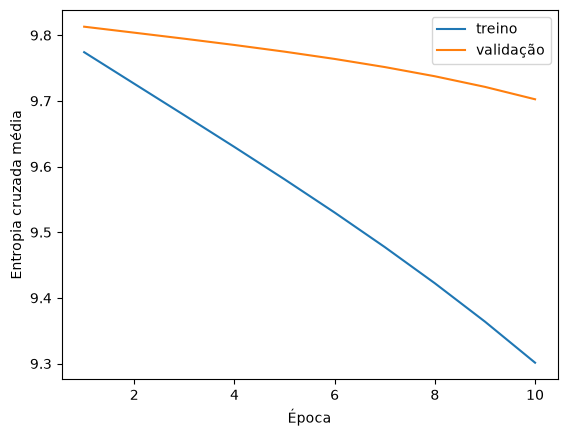

In [90]:
def grafico_historico(*historicos):
    for historico in historicos:
        plt.plot(list(range(1, len(historico[1]) + 1)), historico[1], label=historico[0])
                
    plt.xlabel("Época")
    plt.ylabel("Entropia cruzada média")
    plt.legend()
    plt.show()

grafico_historico(("treino", historico_treino), ("validação", historico_validacao))

In [91]:
configuracao = {
    "tamanho_vocabulario": 16000,
    "tamanho_contexto": 32,
    "dimensao": 32,
    "qtd_cabecas": 4,
}

In [92]:
class GptPequeno(torch.nn.Module):
    def __init__(self, tamanho_vocabulario, tamanho_contexto, dimensao, qtd_cabecas):
        super().__init__()
        self.embedding_tokens = torch.nn.Embedding(tamanho_vocabulario, dimensao)
        self.embedding_posicoes = torch.nn.Embedding(tamanho_contexto, dimensao)
        self.transformer = BlocoTransformer(dimensao, qtd_cabecas)
        self.layer_norm = LayerNorm(dimensao)
        self.projecao_logits = torch.nn.Linear(dimensao, tamanho_vocabulario, bias=False)
    
    def forward(self, x):
        embeddings_tokens = self.embedding_tokens(x)
        indices_posicoes = torch.arange(0, x.shape[1], device=x.device)
        embeddings_posicoes = self.embedding_posicoes(indices_posicoes)
        entrada_transformer = embeddings_tokens + embeddings_posicoes
        saida_transformer = self.transformer(entrada_transformer)
        saida_normalizada = self.layer_norm(saida_transformer)
        logits = self.projecao_logits(saida_normalizada)
        return logits

In [93]:
estado_modelo = gpt_corpus.state_dict()
estado_otimizador = gpt_corpus_sgd.state_dict()

In [94]:
checkpoint = {
    "configuracao": configuracao,
    "estado_modelo": estado_modelo,
    "estado_otimizador": estado_otimizador,
    "historico": {
        "treino": historico_treino,
        "validacao": historico_validacao
    },
    "epocas_adicionais": epocas_adicionais
}

torch.save(checkpoint, "data/checkpoint_gpt_corpus.pt")

In [95]:
checkpoint_carregado = torch.load(
    "data/checkpoint_gpt_corpus.pt", map_location="cpu", weights_only=True
)

gpt_recuperado = GptPequeno(**checkpoint_carregado["configuracao"])
gpt_recuperado.load_state_dict(checkpoint_carregado["estado_modelo"])
epocas_adicionais = checkpoint_carregado["epocas_adicionais"]

In [96]:
gpt_corpus.eval()
gpt_recuperado.eval()
with torch.no_grad():
    print(
        torch.allclose(
            gpt_corpus(loteamento_entradas_validacao[0]),
            gpt_recuperado(loteamento_entradas_validacao[0]),
        )
    )

True


In [97]:
gpt_recuperado_sgd = torch.optim.SGD(gpt_recuperado.parameters(), lr=0.1)
gpt_recuperado_sgd.load_state_dict(checkpoint_carregado["estado_otimizador"])

In [98]:
erro_antes = avaliar_epoca(
    gpt_recuperado, loteamento_entradas_validacao, loteamento_alvo_validacao
)
treino = treinar_epoca(
    gpt_recuperado,
    gpt_recuperado_sgd,
    loteamento_entradas_treino,
    loteamento_alvo_treino,
)
historico_treino.append(treino)
epocas_adicionais += 1
erro_depois = avaliar_epoca(
    gpt_recuperado, loteamento_entradas_validacao, loteamento_alvo_validacao
)
historico_validacao.append(erro_depois)

In [99]:
print("validação antes: ", erro_antes)
print("treino: ", treino)
print("validação depois: ", erro_depois)

validação antes:  9.702425765991212
treino:  9.233732516948994
validação depois:  9.680147234598795


In [100]:
estado_modelo = gpt_recuperado.state_dict()
estado_otimizador = gpt_recuperado_sgd.state_dict()

checkpoint = {
    "configuracao": configuracao,
    "estado_modelo": estado_modelo,
    "estado_otimizador": estado_otimizador,
    "historico": {
        "treino": historico_treino,
        "validacao": historico_validacao
    },
    "epocas_adicionais": epocas_adicionais
}

torch.save(checkpoint, "data/checkpoint_gpt_corpus.pt")

In [101]:
checkpoint_carregado = torch.load(
    "data/checkpoint_gpt_corpus.pt", map_location="cpu", weights_only=True
)

historico_treino = checkpoint_carregado["historico"]["treino"]
historico_validacao = checkpoint_carregado["historico"]["validacao"]
epocas_adicionais = checkpoint_carregado["epocas_adicionais"]
gpt_recuperado = GptPequeno(**checkpoint_carregado["configuracao"])
gpt_recuperado.load_state_dict(checkpoint_carregado["estado_modelo"])
gpt_recuperado_sgd = torch.optim.SGD(gpt_recuperado.parameters(), lr=0.1)
gpt_recuperado_sgd.load_state_dict(checkpoint_carregado["estado_otimizador"])

In [102]:
erro_antes = avaliar_epoca(
    gpt_recuperado, loteamento_entradas_validacao, loteamento_alvo_validacao
)
treino = treinar_epoca(
    gpt_recuperado,
    gpt_recuperado_sgd,
    loteamento_entradas_treino,
    loteamento_alvo_treino,
)
historico_treino.append(treino)
epocas_adicionais += 1
erro_depois = avaliar_epoca(
    gpt_recuperado, loteamento_entradas_validacao, loteamento_alvo_validacao
)
historico_validacao.append(erro_depois)

In [103]:
print("validação antes: ", erro_antes)
print("treino: ", treino)
print("validação depois: ", erro_depois)

validação antes:  9.680147234598795
treino:  9.15981908944937
validação depois:  9.653597831726074


In [104]:
estado_modelo = gpt_recuperado.state_dict()
estado_otimizador = gpt_recuperado_sgd.state_dict()

checkpoint = {
    "configuracao": checkpoint_carregado["configuracao"],
    "estado_modelo": estado_modelo,
    "estado_otimizador": estado_otimizador,
    "historico": {
        "treino": historico_treino,
        "validacao": historico_validacao
    },
    "epocas_adicionais": epocas_adicionais
}

torch.save(checkpoint, "data/checkpoint_gpt_corpus.pt")

In [105]:
def ciclo_epoca(
    modelo,
    otimizador,
    lotes_entrada_treino,
    lotes_alvo_treino,
    lotes_entrada_validacao,
    lotes_alvo_validacao,
    historico_treino,
    historico_validacao,
    qtd_epocas_executadas,
    qtd_epocas,
):
    epocas_adicionais = qtd_epocas_executadas
    posicao_historico_treino = len(historico_treino)
    posicao_historico_validacao = len(historico_validacao)
    for i in range(qtd_epocas):
        print("Epoca: ", qtd_epocas_executadas + i + 1)
        historico_treino.append(
            treinar_epoca(
                modelo,
                otimizador,
                lotes_entrada_treino,
                lotes_alvo_treino,
            )
        )
        epocas_adicionais += 1
        print("Erro médio treino: ", historico_treino[posicao_historico_treino + i])
        historico_validacao.append(
            avaliar_epoca(modelo, lotes_entrada_validacao, lotes_alvo_validacao)
        )
        print(
            "Erro médio validação: ",
            historico_validacao[posicao_historico_validacao + i],
        )

    return epocas_adicionais

In [106]:
def salvar_checkpoint(
    caminho,
    checkpoint_anterior,
    modelo,
    otimizador,
    historico_treino,
    historico_validacao,
    epocas_adicionais,
):
    estado_modelo = modelo.state_dict()
    estado_otimizador = otimizador.state_dict()

    checkpoint = {
        "configuracao": checkpoint_anterior["configuracao"],
        "estado_modelo": estado_modelo,
        "estado_otimizador": estado_otimizador,
        "historico": {"treino": historico_treino, "validacao": historico_validacao},
        "epocas_adicionais": epocas_adicionais,
    }

    torch.save(checkpoint, caminho)

In [107]:
def carregar_checkpoint(caminho):
    try:
        checkpoint = torch.load(caminho, map_location="cpu", weights_only=True)
    except FileNotFoundError:
        checkpoint = {
            "configuracao": {},
            "estado_modelo": {},
            "estado_otimizador": {},
            "historico": {"treino": [], "validacao": []},
            "epocas_adicionais": 0,
        }

    return checkpoint

In [108]:
print(epocas_adicionais, len(historico_treino), len(historico_validacao))

epocas_adicionais = ciclo_epoca(
    gpt_corpus,
    gpt_corpus_sgd,
    loteamento_entradas_treino,
    loteamento_alvo_treino,
    loteamento_entradas_validacao,
    loteamento_alvo_validacao,
    historico_treino,
    historico_validacao,
    epocas_adicionais,
    1,
)

salvar_checkpoint(
    "data/checkpoint_gpt_corpus.pt",
    checkpoint,
    gpt_corpus,
    gpt_corpus_sgd,
    historico_treino,
    historico_validacao,
    epocas_adicionais,
)

12 12 12
Epoca:  13
Erro médio treino:  9.233732516948994
Erro médio validação:  9.680147234598795


In [109]:
novo_checkpoint = carregar_checkpoint("data/checkpoint_gpt_corpus.pt")
print(novo_checkpoint["epocas_adicionais"])
print(len(novo_checkpoint["historico"]["treino"]))
print(len(novo_checkpoint["historico"]["validacao"]))

13
13
13


# Geração de texto

In [110]:
texto_inicial = "Este trabalho tem como objetivo"
tokens_texto_inicial = tokenizador.encode(texto_inicial)
tokens_id_texto_inicial = tokens_texto_inicial.ids
print(tokens_id_texto_inicial)

[2449, 556, 602, 361, 873]


In [112]:
tensor_texto_inicial = torch.tensor([tokens_id_texto_inicial], dtype=torch.long)
print(tensor_texto_inicial)

tensor([[2449,  556,  602,  361,  873]])


In [113]:
tokens_previstos = gerar_tokens(gpt_corpus, tensor_texto_inicial, 10, configuracao["tamanho_contexto"])
print(tokens_previstos)

tensor([[2449,  556,  602,  361,  873]])
tensor([[2449,  556,  602,  361,  873, 4409]])
tensor([[ 2449,   556,   602,   361,   873,  4409, 15622]])
tensor([[ 2449,   556,   602,   361,   873,  4409, 15622,  4055]])
tensor([[ 2449,   556,   602,   361,   873,  4409, 15622,  4055,  2078]])
tensor([[ 2449,   556,   602,   361,   873,  4409, 15622,  4055,  2078,    12]])
tensor([[ 2449,   556,   602,   361,   873,  4409, 15622,  4055,  2078,    12,
         14770]])
tensor([[ 2449,   556,   602,   361,   873,  4409, 15622,  4055,  2078,    12,
         14770,  2432]])
tensor([[ 2449,   556,   602,   361,   873,  4409, 15622,  4055,  2078,    12,
         14770,  2432, 12988]])
tensor([[ 2449,   556,   602,   361,   873,  4409, 15622,  4055,  2078,    12,
         14770,  2432, 12988,    12]])
tensor([[ 2449,   556,   602,   361,   873,  4409, 15622,  4055,  2078,    12,
         14770,  2432, 12988,    12, 14770]])
tensor([[ 2449,   556,   602,   361,   873,  4409, 15622,  4055,  2078,    

In [116]:
tokens_decode = tokens_previstos[0].tolist()
print(tokenizador.decode(tokens_decode))

Este trabalho tem como objetivogma primárias 14 apon, individuo econômica subtropic, individuo
